<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/superposition_minst_bottleneck.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Superposition in a Real Network (MNIST Bottleneck)


In [1]:
import torch
import torchvision, torchvision.datasets as datasets

In [2]:
train_ds = datasets.MNIST("data", train=True, download=True)
test_ds = datasets.MNIST("data", train=False, download=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 41.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.14MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.00MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.52MB/s]


In [3]:
Xtrain = train_ds.data.float().div(255).view(-1,784)
Ytrain = train_ds.targets
Xtest = test_ds.data.float().div(255).view(-1,784)
Ytest = test_ds.targets
print(Xtrain.shape, Ytrain.shape, Xtest.shape, Ytest.shape)

torch.Size([60000, 784]) torch.Size([60000]) torch.Size([10000, 784]) torch.Size([10000])


In [4]:
#number of zero pixels
print('average number of zero pixels' , (Xtrain== 0).float().mean().item())

one_hot = torch.nn.functional.one_hot(Ytrain, num_classes=10).float()
print('Sparcity - ' , (one_hot==0).float().mean().item())
print('class count', torch.bincount(Ytrain))

average number of zero pixels 0.8087977170944214
Sparcity -  0.8999999761581421
class count tensor([5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949])


In [13]:
Xtrain[:5].shape

torch.Size([5, 784])

#Step 2: The bottleneck model
**The architecture is: 784 pixels → 256 (ReLU) → k (the bottleneck) → 10 logits.**

The k-dimensional bottleneck plays the role of the 2D hidden space. The final layer maps the bottleneck to the logits, and each class c reads from the bottleneck along one direction, row c of the last layer’s weight matrix (shape 10 × k). In Day 1 the directions were columns of a (2 × 5) matrix. Here they’re rows of a (10 × k) matrix, so the Gram matrix becomes W_out · W_outᵀ (10 × 10).

In [5]:
import torch.nn as nn

class Bottleneck(nn.Module):
      def __init__(self, k,  hidden=256):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Linear(784, hidden), #scale down to 256 usable features - Shape (64, 256)
            nn.ReLU(), #remove smaller negative values
            nn.Linear(hidden, k) #map to k representation base classes #(64, k)
        )
        self.output = nn.Linear(k, 10) # from k to 10 class representation

      def forward(self, x):
        z = self.enc(x)
        return self.output(z), z


In [6]:
torch.manual_seed(0)
model = Bottleneck(k= 2) # fit in 2 D

logit, z = model(Xtrain[:5])

print(logit.shape, z.shape,model.output.weight.shape, Ytest.shape)

#untrained accuracy
with torch.no_grad():
    accuracy = (model(Xtest)[0].argmax(dim=1) == Ytest).float().mean().item()
    print(accuracy)

torch.Size([5, 10]) torch.Size([5, 2]) torch.Size([10, 2]) torch.Size([10000])
0.08919999748468399


In [7]:
for k in [2, 3, 5, 10]:
  model_k = Bottleneck(k=k)
  print(f"For k = {k} - Numer of Parameters = {sum(p.numel() for p in model_k.parameters())}") #number of parameters does not change much with k as first layer contributes max

For k = 2 - Numer of Parameters = 201504
For k = 3 - Numer of Parameters = 201771
For k = 5 - Numer of Parameters = 202305
For k = 10 - Numer of Parameters = 203640


In [15]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

def train_loop(model, X, Y, epochs=5, batch_size=256, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr= lr)
    n = X.shape[0]
    for epoch in range(epochs):
      permu = torch.randperm(n)
      for i in range(0, n, batch_size):
        idx = permu[i:i + batch_size]
        #print(f"idx = {idx}")
        logits , _ = model(X[idx])
        loss = F.cross_entropy(logits, Y[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()

@torch.no_grad()
def accuracy_of_model(model, x, y):
    logits, _ = model_k(x)
    return (logits.argmax(dim=1) == y).float().mean().item()

minst_models, accuracy_m = {}, {}
ks = [2, 3, 5, 10]
for k in ks:
  torch.manual_seed(0)
  model_k = Bottleneck(k=k)
  train_loop(model_k, Xtrain, Ytrain)
  minst_models[k] = model_k
  accuracy_m[k] = accuracy_of_model(model_k, Xtest, Ytest)
  print(f"For k = {k} - Accuracy = {accuracy_m[k]}", f"Train accuracy = {accuracy_of_model(model_k, Xtrain, Ytrain)}")





For k = 2 - Accuracy = 0.9089000225067139 Train accuracy = 0.9165666699409485
For k = 3 - Accuracy = 0.9480000138282776 Train accuracy = 0.9573833346366882
For k = 5 - Accuracy = 0.9646999835968018 Train accuracy = 0.9717000126838684
For k = 10 - Accuracy = 0.9664999842643738 Train accuracy = 0.9742500185966492


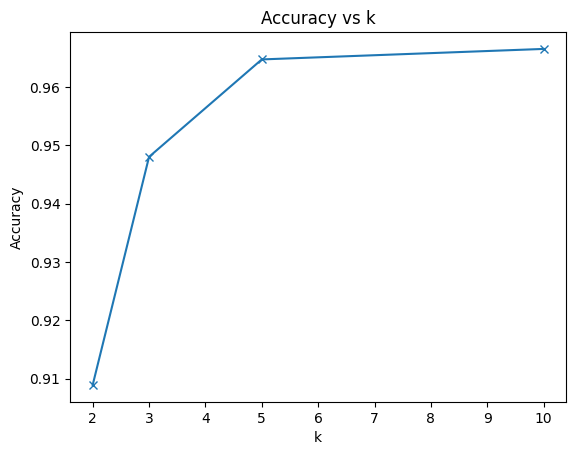

In [14]:
plt.plot(ks, [accuracy_m[k] for k in ks], marker ='x')
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Accuracy vs k")
plt.show()

## Geometric Analysis of Classifier Weights via Softmax-Invariant Centering

To study how the model separates different digit classes in the embedding space ($k$), we analyze the geometry of the final linear layer's weight matrix $W \in \mathbb{R}^{10 \times k}$.

### 1. The Softmax-Invariant Shift
In a standard classification network, the final layer outputs raw scores (logits), which are converted into probabilities using the **Softmax function**:

$$\text{Softmax}(z)_i = \frac{e^{z_i}}{\sum_{j} e^{z_j}}$$

The Softmax function possesses a mathematical property known as **translation invariance**: adding a constant scalar $C$ to every logit changes the raw values but completely cancels out in the fraction, leaving the final probability distribution unchanged:

$$\text{Softmax}(\mathbf{z} + C) = \text{Softmax}(\mathbf{z})$$

### 2. The Need for Centering
Because of this invariance, the model's optimization process does not penalize the final weight vectors if they drift together in a shared, arbitrary direction. If we evaluate the raw weight matrix $W$, it often contains a "shared background bias" or shift vector across all classes. This global shift masks the true relative angles and geometric relationships the model uses to differentiate between classes.

To isolate the genuine class prototypes, we apply **Centering**:

$$W_c = W - \text{mean}(W, \text{dim}=0)$$

Subtracting the mean vector across the class dimension shifts the coordinate system's origin to the true center of the class vectors. This operation:
* **Removes the redundant shift** without altering the network's actual classification boundaries or predictions (as proven by the sanity check below).
* **Isolates the net directional vectors** ($W_c$), allowing us to accurately compute the true Gram matrix (dot products) and Cosine similarities to visualize how evenly the classes are distributed.


torch.Size([10, 2])
0.0


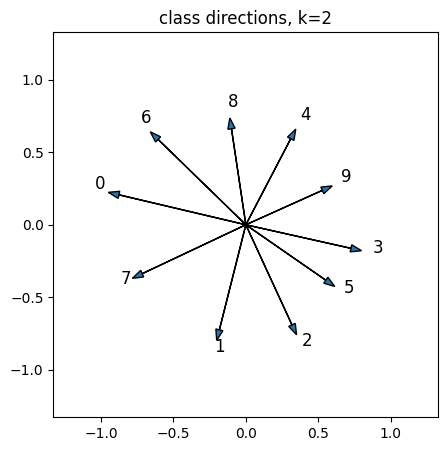

In [31]:
#model with k = 2 sanity test- centering does not change predictions
model_2 = minst_models[2]
print(model_2.output.weight.shape)
z = model_2.enc(Xtest[:1000])
z.shape
pred_1 = (z @ model_2.output.weight.T + model_2.output.bias).argmax(dim=1)
#center the weights to remove softmax shift
Cw = model_2.output.weight - model_2.output.weight.mean(dim=0)
pred_2 = (z @ Cw.T + model_2.output.bias).argmax(dim=1)
print((pred_1 - pred_2).float().mean().item()) # all predictions are same


plt.figure(figsize=(5, 5))
for c in range(10):
    plt.arrow(0, 0, Cw[c, 0].item(), Cw[c, 1].item(), head_width=0.05, length_includes_head=True)
    plt.text(Cw[c, 0].item() * 1.1, Cw[c, 1].item() * 1.1, str(c), fontsize=12)
lim = Cw.abs().max().item() * 1.4
plt.xlim(-lim, lim); plt.ylim(-lim, lim); plt.gca().set_aspect("equal")
plt.title("class directions, k=2");
plt.show()

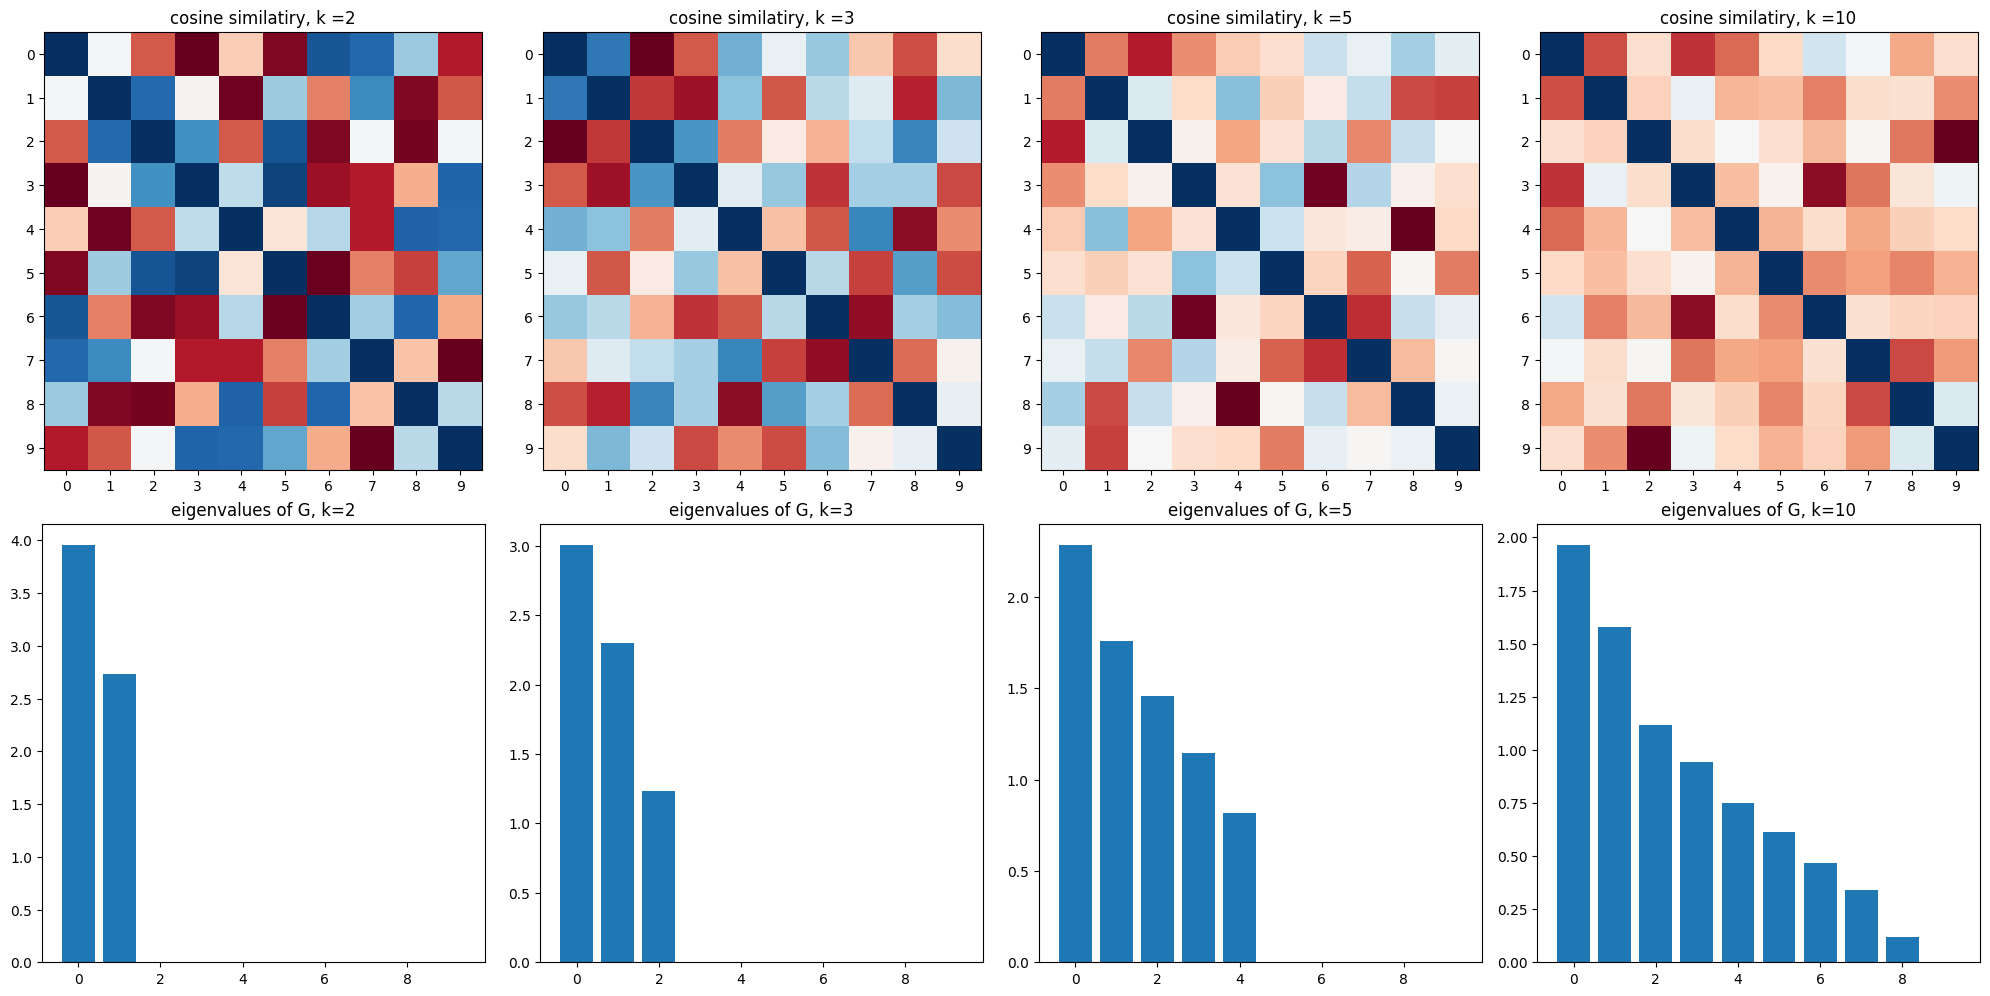

In [30]:
#remove softmax variation and center the weights
def center_direction(model):
  W = model.output.weight
  return W - W.mean(dim=0)

def gram_cosine(Cw):
   G = Cw @ Cw.T
   L = torch.linalg.norm(Cw, dim=1)
   return G, G / (L[:, None] * L[None, :] + 1e-8) # cosine similarity

with torch.no_grad():
  fig, axs = plt.subplots(2, 4, figsize=(20, 10))
  for col, k in enumerate(ks):
    model_k = minst_models[k]
    Cw = center_direction(model_k)
    G, G_cos = gram_cosine(Cw)
    axs[0,col].imshow(G_cos, cmap="RdBu")
    axs[0,col].set_title(f"cosine similatiry, k ={k}")
    axs[0, col].set_xticks(range(10)); axs[0, col].set_yticks(range(10))
    eigen_G = torch.linalg.eigvalsh(G).flip(0) # descending order
    axs[1, col].bar(range(10), eigen_G.numpy())
    axs[1, col].set_title(f"eigenvalues of G, k={k}")
  plt.tight_layout(); plt.show()